# Comparing Four Classification Algorithms

This notebook compares Logistic Regression, Random Forest, Support Vector Machine (SVM), and Decision Tree on the same cleaned dataset and nine input features. Each model gets the same stratified train/test split and the same five cross-validation folds. The aim is to compare how well the algorithms reproduce the dataset's existing `burnout_risk_level` labels, not to diagnose burnout.

## Required imports

We use pandas for tables, matplotlib and seaborn for charts, and scikit-learn for model pipelines, cross-validation, and metrics. `clone` makes a fresh copy of each model configuration for each fold.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style='whitegrid')

## Find the project and cleaned dataset

The cleaned dataset is in `data/processed/`. Checking the current folder and its parent supports running this notebook from either the repository root or a folder directly inside it.

In [2]:
dataset_relative_path = Path('data') / 'processed' / 'cognivault_cleaned_dataset.csv'
possible_project_roots = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (path for path in possible_project_roots if (path / dataset_relative_path).exists()),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        f'Could not find {dataset_relative_path} from the current folder: {Path.cwd()}'
    )

data_path = project_root / dataset_relative_path
df = pd.read_csv(data_path)
print(f'Loaded {len(df)} rows and {len(df.columns)} columns from {data_path}.')

Loaded 1900 rows and 16 columns from d:\Cognivault\data\processed\cognivault_cleaned_dataset.csv.


## Validate the shared feature contract

All four algorithms must use the same nine features, in the same order, to predict `burnout_risk_level`. The score target and student profile/context columns must never enter the input matrix. Using the same inputs makes the comparison meaningful.

In [3]:
features = [
    'study_hours_outside_classes_per_day',
    'academic_tasks_per_week',
    'academic_workload',
    'time_pressure',
    'avg_sleep_hours',
    'wakes_up_tired',
    'physical_activity_days_per_week',
    'difficulty_concentrating',
    'academic_emotional_exhaustion',
]
target = 'burnout_risk_level'
score_target = 'burnout_risk_score'
class_labels = ['Low', 'Moderate', 'High', 'Critical']
profile_context_columns = [
    'institution',
    'degree',
    'year',
    'branch',
    'living_arrangement',
    'student_id',
    'data_source',
]

required_columns = features + [target]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')
if len(features) != 9 or len(set(features)) != 9:
    raise ValueError('Exactly nine unique input features are required.')
if target in features or score_target in features:
    raise ValueError('Target columns must not be used as model inputs.')
leaked_profile_columns = [column for column in profile_context_columns if column in features]
if leaked_profile_columns:
    raise ValueError(f'Profile/context columns entered model inputs: {leaked_profile_columns}')
if df[features].isna().any().any() or df[target].isna().any():
    raise ValueError('Missing values were found in a feature or target column.')
unexpected_labels = sorted(set(df[target]) - set(class_labels))
if unexpected_labels:
    raise ValueError(f'Unexpected target labels: {unexpected_labels}')

X = df.loc[:, features].copy()
y = df[target].copy()
print(f'Feature matrix: {X.shape}')
print(f'Target: {target}')
print(f'Input feature order: {list(X.columns)}')
print('Class counts:')
print(y.value_counts().reindex(class_labels, fill_value=0).to_string())

Feature matrix: (1900, 9)
Target: burnout_risk_level
Input feature order: ['study_hours_outside_classes_per_day', 'academic_tasks_per_week', 'academic_workload', 'time_pressure', 'avg_sleep_hours', 'wakes_up_tired', 'physical_activity_days_per_week', 'difficulty_concentrating', 'academic_emotional_exhaustion']
Class counts:
burnout_risk_level
Low         455
Moderate    687
High        553
Critical    205


## Create the shared stratified train/test split

We split once before comparing models: 80% for training and cross-validation, and 20% for a final test. Stratification keeps each risk class in similar proportions in both sets. The seed `42` makes the split reproducible. The test set is held aside and is not used to compare or select algorithms.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print(f'Training rows: {len(X_train)}')
print(f'Held-out test rows: {len(X_test)}')
print('Training class counts:')
print(y_train.value_counts().reindex(class_labels, fill_value=0).to_string())
print('Test class counts (kept aside until final evaluation):')
print(y_test.value_counts().reindex(class_labels, fill_value=0).to_string())

Training rows: 1520
Held-out test rows: 380
Training class counts:
burnout_risk_level
Low         364
Moderate    550
High        442
Critical    164
Test class counts (kept aside until final evaluation):
burnout_risk_level
Low          91
Moderate    137
High        111
Critical     41


## Define the four existing model configurations

The settings below follow the individual training notebooks: Logistic Regression uses `C=1.0`, balanced class weights, `lbfgs`, and up to 1,000 iterations; Random Forest uses 100 trees and balanced class weights; SVM uses an RBF kernel with `C=1.0` and `gamma='scale'`; Decision Tree uses its documented default split sizes and no maximum depth. All applicable random seeds are 42. Logistic Regression and SVM use `StandardScaler` inside a pipeline because they are scale-sensitive. Tree models do not need scaling. During cross-validation each pipeline is fitted only on that fold's training rows.

We refit each configuration on common folds instead of loading separately saved model files. This ensures every algorithm is evaluated on the same training records and fold boundaries. No hyperparameter tuning is performed.

In [5]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            C=1.0,
            class_weight='balanced',
            solver='lbfgs',
            max_iter=1000,
            random_state=42,
        )),
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1,
    ),
    'Support Vector Machine': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='rbf',
            C=1.0,
            gamma='scale',
            class_weight='balanced',
            random_state=42,
        )),
    ]),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
    ),
}

print('Models configured:')
for model_name in models:
    print(f'- {model_name}')

Models configured:
- Logistic Regression
- Random Forest
- Support Vector Machine
- Decision Tree


## Compare models with the same stratified five folds

Five-fold cross-validation trains on four parts of the training split and validates on the fifth, rotating which part is held out. We create the fold indices once and reuse them for all four algorithms. Macro F1 gives equal weight to each class's F1. High and Critical recall measure the fraction of actual High and Critical records found by the model. The standard deviation describes how much a metric varies across folds; lower variation means more consistent fold results.

In [6]:
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
shared_folds = list(cross_validator.split(X_train, y_train))
cv_records = []

for model_name, base_model in models.items():
    for fold_number, (train_indices, validation_indices) in enumerate(shared_folds, start=1):
        X_fold_train = X_train.iloc[train_indices]
        y_fold_train = y_train.iloc[train_indices]
        X_fold_validation = X_train.iloc[validation_indices]
        y_fold_validation = y_train.iloc[validation_indices]

        fold_model = clone(base_model)
        fold_model.fit(X_fold_train, y_fold_train)
        fold_predictions = fold_model.predict(X_fold_validation)

        cv_records.append({
            'Algorithm': model_name,
            'Fold': fold_number,
            'Macro F1': f1_score(
                y_fold_validation,
                fold_predictions,
                labels=class_labels,
                average='macro',
                zero_division=0,
            ),
            'High recall': recall_score(
                y_fold_validation,
                fold_predictions,
                labels=['High'],
                average=None,
                zero_division=0,
            )[0],
            'Critical recall': recall_score(
                y_fold_validation,
                fold_predictions,
                labels=['Critical'],
                average=None,
                zero_division=0,
            )[0],
        })

cv_results = pd.DataFrame(cv_records)
print('Cross-validation results for every fold (training data only):')
display(cv_results.pivot(index='Fold', columns='Algorithm', values=['Macro F1', 'High recall', 'Critical recall']).round(4))

Cross-validation results for every fold (training data only):


Macro F1                                    \
Algorithm Decision Tree Logistic Regression Random Forest   
Fold                                                        
1                0.7144              0.8795        0.8443   
2                0.8037              0.8431        0.8318   
3                0.7262              0.8481        0.8156   
4                0.7946              0.8773        0.8351   
5                0.7442              0.8559        0.8530   

                                   High recall                      \
Algorithm Support Vector Machine Decision Tree Logistic Regression   
Fold                                                                 
1                         0.8842        0.7079              0.8202   
2                         0.8287        0.7978              0.8315   
3                         0.8346        0.7727              0.8068   
4                         0.8840        0.7045              0.8068   
5                         0.8552        0.6932              0.7727   

                                               Critical recall  \
Algorithm Random Forest Support Vector Machine   Decision Tree   
Fold                                                             
1                0.8202                 0.8539          0.5938   
2                0.8090                 0.7640          0.8788   
3                0.7727                 0.7386          0.6667   
4                0.7500                 0.8182          0.8182   
5                0.7955                 0.7841          0.7273   

                                                                    
Algorithm Logistic Regression Random Forest Support Vector Machine  
Fold                                                                
1                      0.9688        0.8125                 0.9375  
2                      0.9091        0.8788                 0.9394  
3                      0.9091        0.7879                 0.9091  
4                      0.9394        0.9394                 0.9394  
5                      0.9697        0.8485                 0.9394

## Summary table and metric charts

The table shows each algorithm's average score across the five folds and its fold-to-fold standard deviation. The three charts make it easier to compare overall class balance (Macro F1) and recall for the two higher-risk labels. These are cross-validation results; the test set has not been used.

,Mean Macro F1,Mean High recall,Mean Critical recall
Algorithm,,,
Logistic Regression,0.8608,0.8076,0.9392
Random Forest,0.8359,0.7895,0.8534
Support Vector Machine,0.8574,0.7918,0.9330
Decision Tree,0.7566,0.7352,0.7369


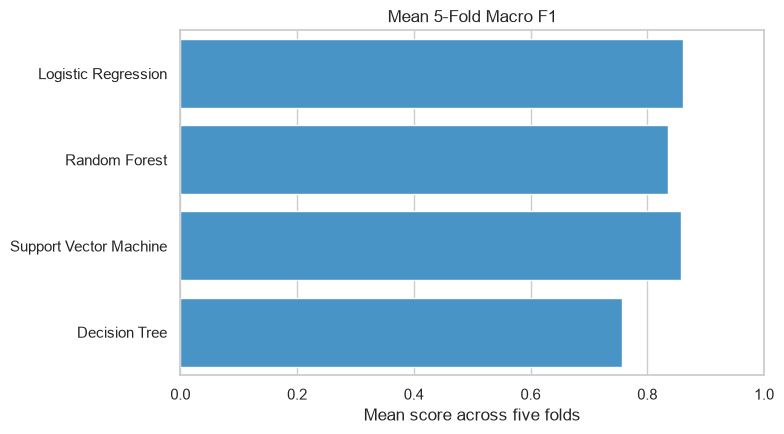

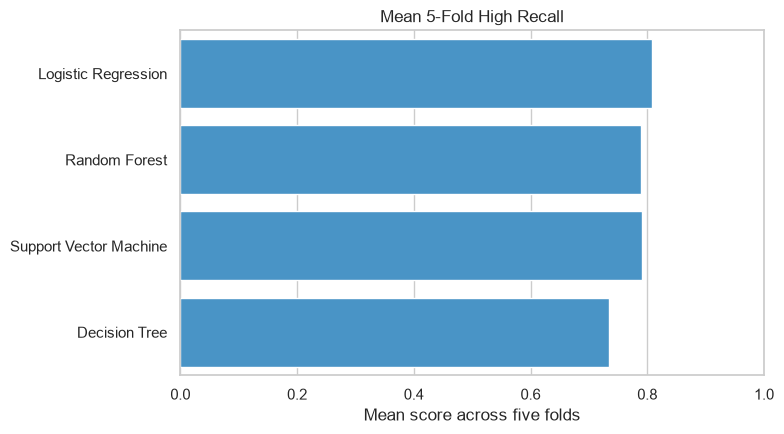

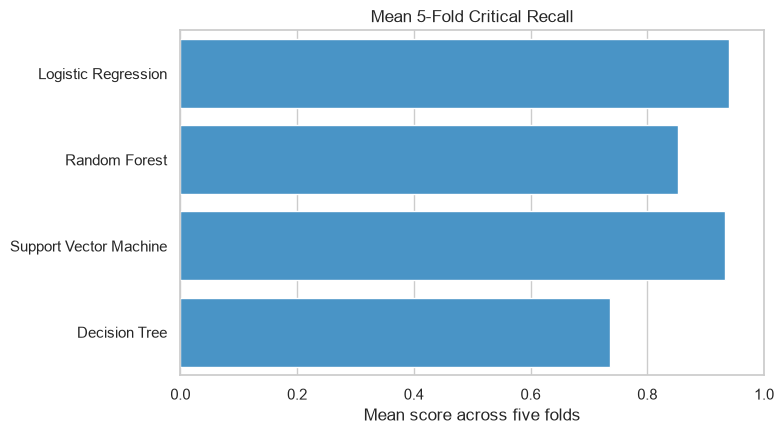

In [12]:
summary_rows = []
for model_name in models:
    model_results = cv_results[cv_results['Algorithm'] == model_name]
    summary_rows.append({
        'Algorithm': model_name,
        'Mean Macro F1': model_results['Macro F1'].mean(),
        'Mean High recall': model_results['High recall'].mean(),
        'Mean Critical recall': model_results['Critical recall'].mean(),
    })

comparison_table = pd.DataFrame(summary_rows).set_index('Algorithm')
display(comparison_table.round(4))

chart_metrics = [
    ('Mean Macro F1', 'Mean 5-Fold Macro F1'),
    ('Mean High recall', 'Mean 5-Fold High Recall'),
    ('Mean Critical recall', 'Mean 5-Fold Critical Recall'),
]

for metric_column, chart_title in chart_metrics:
    plt.figure(figsize=(8, 4.5))
    sns.barplot(
        data=comparison_table.reset_index(),
        x=metric_column,
        y='Algorithm',
        color='#3498db',
    )
    plt.xlim(0, 1)
    plt.xlabel('Mean score across five folds')
    plt.ylabel('')
    plt.title(chart_title)
    plt.tight_layout()
    plt.show()

## Choose a candidate using cross-validation only

Macro F1 summarizes performance across all four classes, while High and Critical recall focus on finding those labels. A model can lead on one measure and trail on another, so we do not choose by Macro F1 alone. For a simple, transparent comparison rule, this notebook gives equal weight to the three cross-validation means (Macro F1, High recall, and Critical recall) and selects the highest average. This is a project comparison heuristic, not a clinical cost model; read the individual metrics and standard deviations before interpreting the result. The held-out test set is not involved in this choice.

In [8]:
comparison_table['Balanced CV score'] = comparison_table[
    ['Mean Macro F1', 'Mean High recall', 'Mean Critical recall']
].mean(axis=1)
selected_model_name = comparison_table['Balanced CV score'].idxmax()

print('Algorithm with highest mean Macro F1:', comparison_table['Mean Macro F1'].idxmax())
print('Algorithm with highest mean High recall:', comparison_table['Mean High recall'].idxmax())
print('Algorithm with highest mean Critical recall:', comparison_table['Mean Critical recall'].idxmax())
print('Candidate selected by the equal-weight CV rule:', selected_model_name)
print(f'Balanced CV score: {comparison_table.loc[selected_model_name, "Balanced CV score"]:.4f}')
print('Review the table for trade-offs and fold variability before treating this as a recommendation.')
display(comparison_table[['Mean Macro F1', 'Mean High recall', 'Mean Critical recall', 'Balanced CV score']].sort_values('Balanced CV score', ascending=False).round(4))

Algorithm with highest mean Macro F1: Logistic Regression
Algorithm with highest mean High recall: Logistic Regression
Algorithm with highest mean Critical recall: Logistic Regression
Candidate selected by the equal-weight CV rule: Logistic Regression
Balanced CV score: 0.8692
Review the table for trade-offs and fold variability before treating this as a recommendation.


,Mean Macro F1,Mean High recall,Mean Critical recall,Balanced CV score
Algorithm,,,,
Logistic Regression,0.8608,0.8076,0.9392,0.8692
Support Vector Machine,0.8574,0.7918,0.9330,0.8607
Random Forest,0.8359,0.7895,0.8534,0.8263
Decision Tree,0.7566,0.7352,0.7369,0.7429


## Final evaluation of the selected candidate

Only after selecting a candidate from cross-validation do we fit that model on the complete training split and evaluate it on the held-out test split. These test metrics are a final estimate for the selected candidate, not a way to revisit the algorithm choice. Accuracy is the fraction of all test records classified correctly. Precision measures how often predictions for a class are right; recall measures how many actual records of that class are found. F1 combines precision and recall. Support is the number of true test examples in each class.

In [9]:
selected_model = clone(models[selected_model_name])
selected_model.fit(X_train, y_train)
test_predictions = selected_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    labels=class_labels,
    average='macro',
    zero_division=0,
)
test_report = classification_report(
    y_test,
    test_predictions,
    labels=class_labels,
    target_names=class_labels,
    output_dict=True,
    zero_division=0,
)
test_metrics_by_class = pd.DataFrame(test_report).T.loc[
    class_labels,
    ['precision', 'recall', 'f1-score', 'support'],
]

print(f'Selected candidate: {selected_model_name}')
print(f'Held-out test accuracy: {test_accuracy:.4f}')
print(f'Held-out test macro F1: {test_macro_f1:.4f}')
print(f'Held-out test High recall: {test_report["High"]["recall"]:.4f}')
print(f'Held-out test Critical recall: {test_report["Critical"]["recall"]:.4f}')
print('Per-class held-out test metrics:')
display(test_metrics_by_class.round(4))

Selected candidate: Logistic Regression
Held-out test accuracy: 0.8395
Held-out test macro F1: 0.8361
Held-out test High recall: 0.7928
Held-out test Critical recall: 0.8049
Per-class held-out test metrics:


,precision,recall,f1-score,support
Low,0.8969,0.9560,0.9255,91.0
Moderate,0.8605,0.8102,0.8346,137.0
High,0.7857,0.7928,0.7892,111.0
Critical,0.7857,0.8049,0.7952,41.0


## Confusion matrix for the selected candidate

Rows are actual test labels and columns are predicted labels. Counts on the diagonal are correct classifications. Off-diagonal counts show which risk levels were confused.

Predicted,Low,Moderate,High,Critical
Actual,,,,
Low,87,4,0,0
Moderate,10,111,16,0
High,0,14,88,9
Critical,0,0,8,33


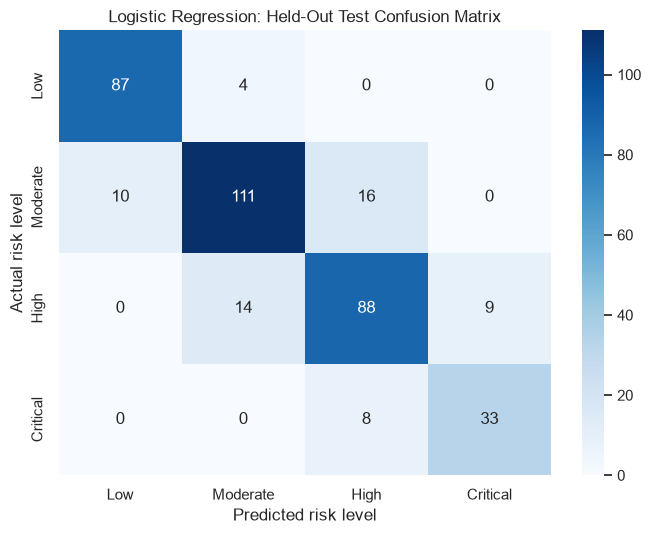

In [10]:
test_confusion_counts = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels,
)
test_confusion_table = pd.DataFrame(
    test_confusion_counts,
    index=pd.Index(class_labels, name='Actual'),
    columns=pd.Index(class_labels, name='Predicted'),
)
display(test_confusion_table)

plt.figure(figsize=(7, 5.5))
sns.heatmap(test_confusion_table, annot=True, fmt='d', cmap='Blues')
plt.title(f'{selected_model_name}: Held-Out Test Confusion Matrix')
plt.xlabel('Predicted risk level')
plt.ylabel('Actual risk level')
plt.tight_layout()
plt.show()